# Algoritmos de clasificación

**Estudiante:** David Alonso Torres Rivas  
**Programa:** Especialización en Analítica y Ciencia de Datos  
**Asignatura:** Machine Learning  

**Propósito:**
 Aplicar cinco algoritmos de clasificación sobre un mismo caso, evaluar sus resultados
y justificar cuál sería la alternativa más adecuada según el problema y las métricas obtenidas.

## 1. Carga de datos y variable objetivo

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report, ConfusionMatrixDisplay

RANDOM_STATE=42
data=load_breast_cancer(as_frame=True)

X=data.data.copy()

# La guía pide 1=maligno y 0=benigno; tener en cuenta que sklearn tiene la codificación inversa.

y=(data.target==0).astype(int)
print("Dimensiones:",X.shape)
print("Distribución 0=benigno, 1=maligno:")
print(y.value_counts().sort_index())
print("Valores faltantes:",X.isna().sum().sum())

Dimensiones: (569, 30)
Distribución 0=benigno, 1=maligno:
target
0    357
1    212
Name: count, dtype: int64
Valores faltantes: 0


El conjunto tiene 569 observaciones y 30 variables predictoras. La clase positiva se define como maligno (1), siguiendo la guía. Por eso Recall mide qué proporción de los casos malignos reales identifica el modelo.

## 2. División común entrenamiento/prueba

In [12]:
X_train,X_test,y_train,y_test=train_test_split(X,y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Entrenamiento:",X_train.shape,"Prueba:",X_test.shape)
print("Proporción de malignos en entrenamiento:",round(y_train.mean(),3))
print("Proporción de malignos en prueba:",round(y_test.mean(),3))

Entrenamiento: (455, 30) Prueba: (114, 30)
Proporción de malignos en entrenamiento: 0.374
Proporción de malignos en prueba: 0.368


## 3. Función común de evaluación

In [14]:
def evaluar_modelo(nombre,modelo,X_eval,y_eval):
    pred=modelo.predict(X_eval)
    
    metricas={"Modelo":nombre,
              "Accuracy":accuracy_score(y_eval,pred),
              "Precision":precision_score(y_eval,pred,zero_division=0),
              "Recall":recall_score(y_eval,pred,zero_division=0),
              "F1-score":f1_score(y_eval,pred,zero_division=0)
             }
    
    # Filas=clase real, columnas=predicción; orden: benigno (0), maligno (1).
    
    cm=confusion_matrix(y_eval,pred,labels=[0,1])
    print(nombre,"\n",cm)
    print(classification_report(y_eval,pred,target_names=["Benigno (0)","Maligno (1)"],zero_division=0))
    return metricas,pred,cm

## 4. Decision Tree

Limitar la profundidad a cuatro niveles facilita la interpretación y puede reducir el sobreajuste.

In [15]:
modelo_dt=DecisionTreeClassifier(max_depth=4,random_state=RANDOM_STATE)

modelo_dt.fit(X_train,y_train)
res_dt,pred_dt,cm_dt=evaluar_modelo("Decision Tree",modelo_dt,X_test,y_test)

Decision Tree 
 [[70  2]
 [ 8 34]]
              precision    recall  f1-score   support

 Benigno (0)       0.90      0.97      0.93        72
 Maligno (1)       0.94      0.81      0.87        42

    accuracy                           0.91       114
   macro avg       0.92      0.89      0.90       114
weighted avg       0.91      0.91      0.91       114



## 5. Random Forest

Combina 100 árboles; el conjunto puede reducir la variabilidad de un árbol individual.

In [16]:
modelo_rf=RandomForestClassifier(n_estimators=100,random_state=RANDOM_STATE)

modelo_rf.fit(X_train,y_train)
res_rf,pred_rf,cm_rf=evaluar_modelo("Random Forest",modelo_rf,X_test,y_test)

Random Forest 
 [[72  0]
 [ 3 39]]
              precision    recall  f1-score   support

 Benigno (0)       0.96      1.00      0.98        72
 Maligno (1)       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



## 6. Support Vector Machine (SVM)

Se usa kernel RBF y StandardScaler dentro de Pipeline porque SVM es sensible a la escala.

In [18]:
modelo_svm=make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, gamma="scale")
)

modelo_svm.fit(X_train,y_train)
res_svm,pred_svm,cm_svm=evaluar_modelo("SVM",modelo_svm,X_test,y_test)

SVM 
 [[72  0]
 [ 3 39]]
              precision    recall  f1-score   support

 Benigno (0)       0.96      1.00      0.98        72
 Maligno (1)       1.00      0.93      0.96        42

    accuracy                           0.97       114
   macro avg       0.98      0.96      0.97       114
weighted avg       0.97      0.97      0.97       114



## 7. K-Nearest Neighbors (K-NN)

k=5 significa que se consideran los cinco vecinos más cercanos. El escalamiento es importante porque el algoritmo usa distancias.

In [19]:
modelo_knn=make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=5))

modelo_knn.fit(X_train,y_train)
res_knn,pred_knn,cm_knn=evaluar_modelo("K-NN",modelo_knn,X_test,y_test)

K-NN 
 [[71  1]
 [ 4 38]]
              precision    recall  f1-score   support

 Benigno (0)       0.95      0.99      0.97        72
 Maligno (1)       0.97      0.90      0.94        42

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



## 8. Naive Bayes

GaussianNB se usa sin escalamiento, según la guía. Supone independencia condicional entre predictores dada la clase.

In [20]:
modelo_nb=GaussianNB()

modelo_nb.fit(X_train,y_train)
res_nb,pred_nb,cm_nb=evaluar_modelo("Naive Bayes",modelo_nb,X_test,y_test)

Naive Bayes 
 [[72  0]
 [ 7 35]]
              precision    recall  f1-score   support

 Benigno (0)       0.91      1.00      0.95        72
 Maligno (1)       1.00      0.83      0.91        42

    accuracy                           0.94       114
   macro avg       0.96      0.92      0.93       114
weighted avg       0.94      0.94      0.94       114



## 9. Comparación consolidada

,Modelo,Accuracy,Precision,Recall,F1-score
0,Random Forest,0.9737,1.0000,0.9286,0.9630
1,SVM,0.9737,1.0000,0.9286,0.9630
2,K-NN,0.9561,0.9744,0.9048,0.9383
3,Naive Bayes,0.9386,1.0000,0.8333,0.9091
4,Decision Tree,0.9123,0.9444,0.8095,0.8718


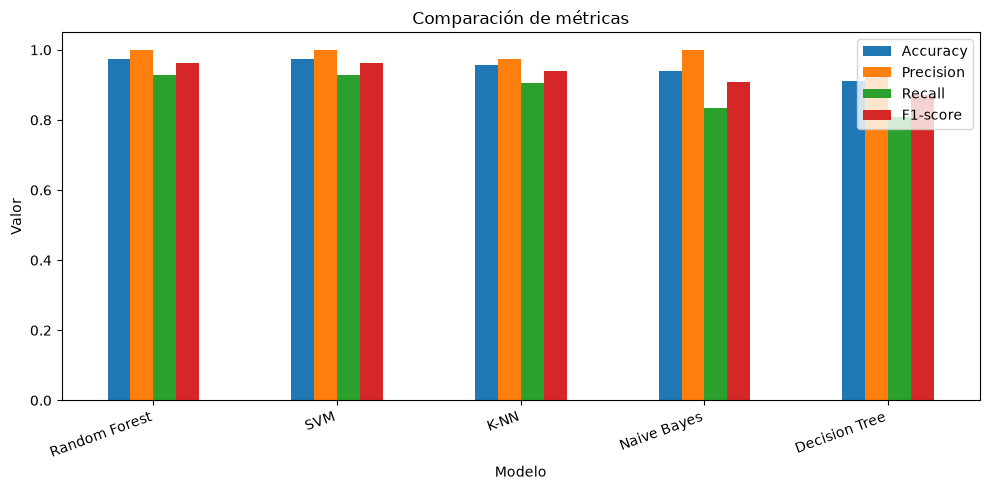

In [21]:
comparacion=pd.DataFrame([res_dt,res_rf,res_svm,res_knn,res_nb])
comparacion=comparacion.sort_values(["Recall","F1-score","Accuracy"],ascending=False).reset_index(drop=True)

display(comparacion.style.format({c:"{:.4f}" for c in ["Accuracy","Precision","Recall","F1-score"]}))
ax=comparacion.set_index("Modelo")[["Accuracy","Precision","Recall","F1-score"]].plot(kind="bar",figsize=(10,5),ylim=(0,1.05))
ax.set_ylabel("Valor"); ax.set_title("Comparación de métricas"); plt.xticks(rotation=20,ha="right"); plt.tight_layout(); plt.show()

## 10. Matrices y tipos de error

In [1]:
matrices={"Decision Tree":cm_dt,"Random Forest":cm_rf,"SVM":cm_svm,"K-NN":cm_knn,"Naive Bayes":cm_nb}
filas=[]
for nombre,cm in matrices.items():
    tn,fp,fn,tp=cm.ravel()
    filas.append({"Modelo":nombre,"Verdaderos negativos":tn,"Falsos positivos":fp,"Falsos negativos":fn,"Verdaderos positivos":tp})
    ConfusionMatrixDisplay(cm,display_labels=["Benigno (0)","Maligno (1)"]).plot(values_format="d")
    plt.title("Matriz de confusión — "+nombre); plt.show()
errores_df=pd.DataFrame(filas).sort_values("Falsos negativos")
display(errores_df)

Los falsos negativos son casos malignos que el modelo predice como benignos. Reducirlos es importante para este objetivo, aunque puede incrementar los falsos positivos. La decisión debe considerar ambos errores, además de las métricas generales.

## 11. Selección del modelo

In [1]:
seleccion=comparacion.sort_values(["Recall","F1-score","Accuracy"],ascending=False).iloc[0]
print("Modelo seleccionado:",seleccion["Modelo"])
print(seleccion[["Accuracy","Precision","Recall","F1-score"]])

La selección prioriza Recall de la clase maligna, usando F1-score y Accuracy como criterios secundarios. Recall alto significa que se detecta una mayor proporción de los casos malignos reales. Esta decisión solo se refiere a la comparación académica y no demuestra utilidad clínica.

## 12. Conclusiones

- Los cinco algoritmos usan la misma partición 80/20, estratificada y reproducible.
- SVM y K-NN se escalaron mediante Pipeline; los otros se entrenaron sin escalamiento, siguiendo la guía.
- Accuracy, Precision, Recall, F1-score y matrices de confusión deben interpretarse en conjunto.
- Para este caso se prioriza Recall de la clase maligna, con F1-score y Accuracy como criterios secundarios.
- El orden de desempeño puede cambiar con otros parámetros o particiones.
- El ejercicio no debe utilizarse para diagnóstico médico.

## 13. Referencias

- Scikit-learn. (s. f.). *Breast cancer Wisconsin (diagnostic) dataset*. https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html
- Scikit-learn. (s. f.). *Classification metrics*. https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics
- UCI Machine Learning Repository. (s. f.). *Breast Cancer Wisconsin (Diagnostic)*. https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- Universidad de Cundinamarca. (2026). *Semana 8: Implementación y comparación de algoritmos de clasificación. Guía de trabajo asincrónico*.